# Graph ablation

Does the connectome help the G-VAR models, and is it the *synaptic* wiring that helps or just having neighbours? Each model is run with three graphs, at the same $P = 15$, $K = 3$ and training settings (patience 6, 30 epochs for the nonlinear models):

- **connectome**: the 947 proofread synapses, weighted by synapse count.
- **random**: as many edges between random pairs of neurons, with the synapse weights shuffled. Same parameter count as the connectome model.
- **no graph**: $\mathbf{S} = \mathbf{0}$, so every $k \geq 1$ term vanishes, in the linear backbone and in the nonlinear graph filters. The linear models become a shared AR(15) per neuron. The nonlinear models add an MLP applied to each neuron separately, with weights shared across neurons.

The seed sets the random graph and the network initialisation. The closed-form fits on a fixed graph are deterministic, so they get one seed. The nonlinear models get seeds 0–2, so the graph effect can be compared with run-to-run noise.

The run list is in `ablation.py`. Results are read from `runs/`. Set `TRAIN = True` to fit or train the missing runs (or run `python ablation.py`).

In [1]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import ablation
from data import DATASETS

TRAIN = False  # fit or train missing runs (nonlinear runs take 4-20 min each)
if TRAIN:
    ablation.train_missing()

GRAPHS = {'connectome': 'connectome', 'random': 'random graph', 'none': 'no graph'}
COLORS = {'connectome': '#eb6834', 'random': '#2a78d6', 'none': '#a3a29b'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'lines.linewidth': 2, 'figure.dpi': 110})

df = ablation.results()
expected = pd.DataFrame([(m, g, s) for m, g, s, *_ in ablation.configs()], columns=['model', 'graph', 'seed'])
missing = expected.merge(df[['model', 'graph', 'seed']], how='left', indicator=True).query('_merge == "left_only"')
print(f'{len(df)} of {len(expected)} runs found')
if len(missing):
    print('missing:'); print(missing.drop(columns='_merge').to_string(index=False))

28 of 28 runs found


## Test MSE by graph

Mean over seeds (± standard deviation where there is more than one), in standardised log1p units. *avg* is the mean over horizons 1 to 5. The Δ columns are relative to the same model without a graph; negative means the graph helps.

In [2]:
models = list(ablation.MODELS)
g = df.groupby(['model', 'graph'], sort=False)
mean, std, n = g[['h1', 'h5', 'avg']].mean(), g[['h1', 'h5', 'avg']].std(), g.size()

def fmt(m, s):
    return f'{m:.4f}' if np.isnan(s) else f'{m:.4f} ± {s:.4f}'

rows = {}
for (model, graph), m in mean.iterrows():
    s, none = std.loc[(model, graph)], mean.loc[(model, 'none')] if (model, 'none') in mean.index else None
    row = {('MSE', k): fmt(m[k], s[k]) for k in ('h1', 'h5', 'avg')}
    row.update({('Δ vs no graph', k): '' if none is None or graph == 'none' else f'{m[k] - none[k]:+.4f}'
                for k in ('h1', 'h5', 'avg')})
    row[('', 'seeds')] = n.loc[(model, graph)]
    rows[(model, GRAPHS[graph])] = row
table = pd.DataFrame(rows).T
table.columns = pd.MultiIndex.from_tuples(table.columns)
table

MSE                   \
                                                     h1               h5   
G-VAR                     connectome             0.4216           0.7333   
                          random graph  0.4221 ± 0.0000  0.7336 ± 0.0000   
                          no graph               0.4221           0.7337   
direct G-VAR              connectome             0.4216           0.7294   
                          random graph  0.4221 ± 0.0000  0.7297 ± 0.0000   
                          no graph               0.4221           0.7297   
nonlinear G-VAR (direct)  connectome    0.3485 ± 0.0025  0.7245 ± 0.0003   
                          random graph  0.3503 ± 0.0022  0.7257 ± 0.0007   
                          no graph      0.3478 ± 0.0015  0.7257 ± 0.0001   
nonlinear G-VAR (rollout) connectome    0.3624 ± 0.0034  0.7253 ± 0.0005   
                          random graph  0.3674 ± 0.0083  0.7261 ± 0.0006   
                          no graph      0.3677 ± 0.0061  0.7255 ± 0.0008   

                                                        Δ vs no graph  \
                                                    avg            h1   
G-VAR                     connectome             0.6656       -0.0005   
                          random graph  0.6662 ± 0.0000       -0.0001   
                          no graph               0.6662                 
direct G-VAR              connectome             0.6638       -0.0005   
                          random graph  0.6644 ± 0.0000       -0.0001   
                          no graph               0.6644                 
nonlinear G-VAR (direct)  connectome    0.6420 ± 0.0005       +0.0007   
                          random graph  0.6433 ± 0.0009       +0.0024   
                          no graph      0.6427 ± 0.0004                 
nonlinear G-VAR (rollout) connectome    0.6452 ± 0.0006       -0.0053   
                          random graph  0.6469 ± 0.0021       -0.0003   
                          no graph      0.6468 ± 0.0014                 

                                                                
                                             h5      avg seeds  
G-VAR                     connectome    -0.0004  -0.0006     1  
                          random graph  -0.0000  -0.0001     3  
                          no graph                           1  
direct G-VAR              connectome    -0.0004  -0.0006     1  
                          random graph  -0.0000  -0.0001     3  
                          no graph                           1  
nonlinear G-VAR (direct)  connectome    -0.0012  -0.0007     3  
                          random graph  -0.0000  +0.0006     3  
                          no graph                           3  
nonlinear G-VAR (rollout) connectome    -0.0002  -0.0015     3  
                          random graph  +0.0005  +0.0002     3  
                          no graph                           3

## Graph effect per horizon

Change in test MSE relative to the no-graph model (mean over its seeds), per forecast horizon. The lines are seed means, the dots single seeds. A line below zero means the graph helps at that horizon. Dots far from their line mean the run-to-run noise is as big as the effect.

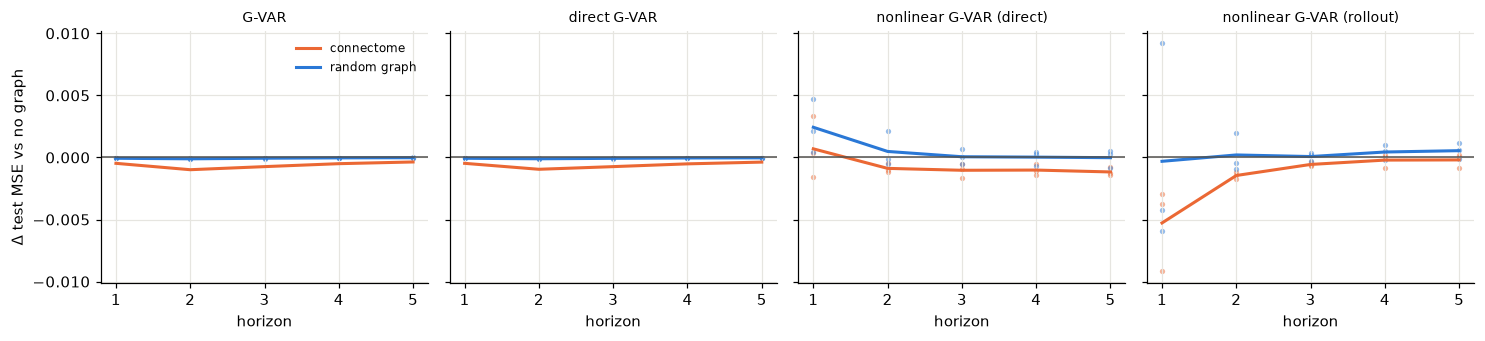

In [3]:
fig, axes = plt.subplots(1, len(models), figsize=(3.4 * len(models), 3.2), sharey=True)
for ax, model in zip(axes, models):
    d = df[df.model == model]
    if not (d.graph == 'none').any():
        ax.set_title(f'{model}\n(no-graph run missing)', fontsize=9)
        continue
    base = np.mean(np.stack(d[d.graph == 'none'].mse), 0)
    hs = np.arange(1, len(base) + 1)
    for graph in ('connectome', 'random'):
        runs = np.stack(d[d.graph == graph].mse) - base if (d.graph == graph).any() else None
        if runs is None:
            continue
        ax.plot(hs, runs.mean(0), color=COLORS[graph], label=GRAPHS[graph])
        if len(runs) > 1:
            for r in runs:
                ax.scatter(hs, r, s=12, color=COLORS[graph], alpha=0.5, linewidths=0)
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.set(title=model, xlabel='horizon', xticks=hs)
    ax.title.set_fontsize(9)
axes[0].set_ylabel('Δ test MSE vs no graph')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Which neurons does the graph help?

Neurons without presynaptic partners only see the $k = 0$ term, so the connectome can only help neurons with inputs. Below is the per-neuron change in $h = 1$ test MSE relative to the no-graph model, grouped by connectome in-degree (mean over seeds). Random-graph neurons are grouped by their *connectome* in-degree too, so each group holds the same neurons.

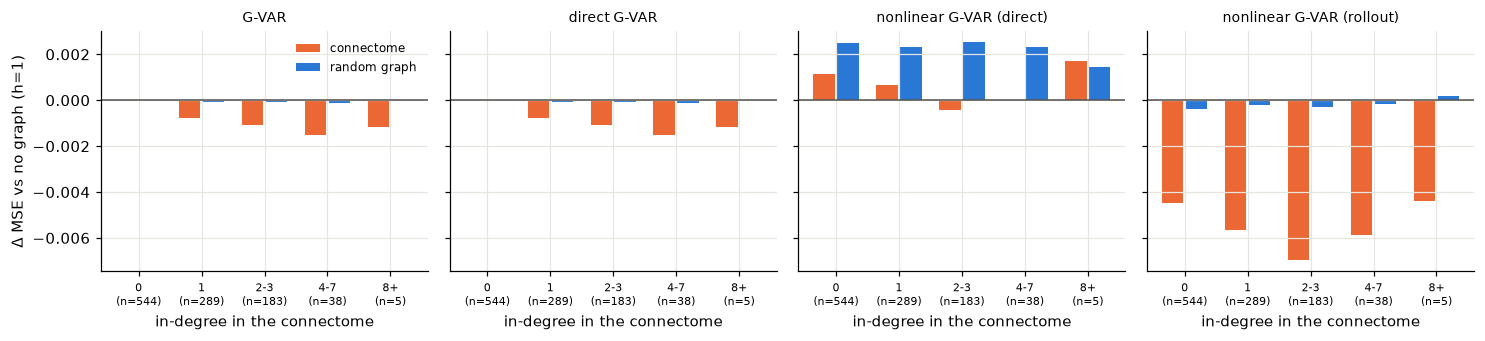

In [4]:
edge_index = torch.load(f"{DATASETS['cave_proofread']}/edge_index.pt")
N = len(df.per_neuron_h1.iloc[0])
indeg = np.bincount(edge_index[1].numpy(), minlength=N)
bins, labels = [0, 1, 2, 4, 8, np.inf], ['0', '1', '2-3', '4-7', '8+']
group = pd.cut(indeg, bins, right=False, labels=labels)
counts = pd.Series(group).value_counts().reindex(labels).fillna(0).astype(int)

def per_neuron(model, graph):
    d = df[(df.model == model) & (df.graph == graph)]
    return np.mean(np.stack(d.per_neuron_h1), 0) if len(d) else None

fig, axes = plt.subplots(1, len(models), figsize=(3.4 * len(models), 3.2), sharey=True)
width = 0.38
for ax, model in zip(axes, models):
    base = per_neuron(model, 'none')
    if base is None:
        ax.set_title(f'{model}\n(no-graph run missing)', fontsize=9)
        continue
    for i, graph in enumerate(('connectome', 'random')):
        v = per_neuron(model, graph)
        if v is not None:
            means = pd.Series(v - base).groupby(group, observed=False).mean()
            ax.bar(np.arange(len(labels)) + (i - 0.5) * width, means.values, width - 0.04,
                   color=COLORS[graph], label=GRAPHS[graph])
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.set_xticks(np.arange(len(labels)), [f'{l}\n(n={c})' for l, c in zip(labels, counts)], fontsize=7)
    ax.set(title=model, xlabel='in-degree in the connectome')
    ax.title.set_fontsize(9)
axes[0].set_ylabel('Δ MSE vs no graph (h=1)')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Takeaways

- **The graph adds very little, at most about 0.001 test MSE (about 0.15%).** Nearly all of the gain of the nonlinear models over the linear G-VAR (h=1: 0.42 → 0.35) comes from the nonlinearity applied to each neuron's own history, not from the graph.
- **Linear models: a small, real connectome effect.** The fit is deterministic, so this isn't noise. The connectome lowers the MSE at every horizon, and the gain grows with in-degree. Neurons with no presynaptic partners are unchanged, as they should be. A random graph with the same number of edges gives nothing. So it is the synaptic wiring that helps, not just having neighbours, but the effect is tiny.
- **Nonlinear G-VAR (direct), 3 seeds:**
  - At h=1 the graph effect is within the seed spread (about ±0.002). The per-neuron plot confirms this is noise: the h=1 change is about the same at every in-degree, including in-degree 0, where the graph can't act.
  - At h≥2 the connectome is about 0.001 better than no graph, on every seed.
  - The random graph is never better than no graph.
- **Nonlinear G-VAR (rollout), 3 seeds:**
  - On the seed mean, the connectome looks better at h=1 (0.362 vs 0.368 for no graph and 0.367 for the random graph).
  - Paired by seed, the h=1 differences (connectome − no graph) are −0.0001, −0.016 and +0.0005. The whole gap comes from no-graph seed 1, which early-stopped at epoch 16 (h=1 0.375).
  - The per-neuron plot agrees: neurons with in-degree 0, which never receive graph input, gain as much as the rest. So this is training variance, not information carried by the graph.
  - Rollout training is noisier than direct training: best epochs range from 12 to 30, and h=1 MSE varies by up to 0.014 between seeds. The connectome runs happen to be the most consistent (avg 0.6452 ± 0.0006, vs 0.6468 ± 0.0014 for no graph and 0.6469 ± 0.0021 for the random graph). Over the 1–5 average, the connectome is about 0.0004 better than no graph on two seeds, which is at the noise level.
- **For the report:** the connectome is a weak but correctly signed prior. It helps neurons with more synaptic inputs and helps more at longer horizons, and a random graph doesn't reproduce that. But it is far smaller than the gains from the nonlinearity. One possible cause is that only 947 proofread edges cover 1,059 neurons: 544 neurons have no presynaptic partner in the graph.
